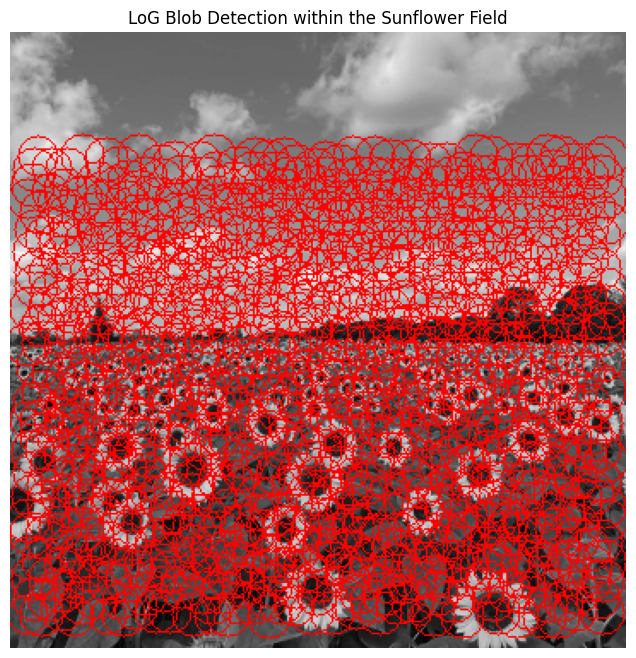

Sigma range: 1.0 to 9.5
Total detections within ROI: 889

Largest 10 circles:
Rank | x | y | Radius | Sigma | Response
   1 |  261 |  199 |  13.44 |  9.5 | 722.00
   2 |  338 |  302 |  13.44 |  9.5 | 722.00
   3 |  145 |  199 |  13.44 |  9.5 | 722.00
   4 |   69 |  214 |  13.44 |  9.5 | 722.00
   5 |   84 |  214 |  13.44 |  9.5 | 722.00
   6 |   33 |  202 |  13.44 |  9.5 | 722.00
   7 |   74 |  202 |  13.44 |  9.5 | 722.00
   8 |  208 |  213 |  13.44 |  9.5 | 722.00
   9 |   84 |  204 |  13.44 |  9.5 | 722.00
  10 |  256 |  215 |  13.44 |  9.5 | 722.00


In [14]:
# 4. Create a region of interest (ROI)
h, w = img.shape

# Exclude the upper sky and extreme image boundaries
roi = np.zeros((h, w), dtype=np.uint8)
roi[int(0.20*h):int(0.95*h),
    int(0.03*w):int(0.97*w)] = 1

# 5. Find local maxima across space and scale
from scipy.ndimage import maximum_filter

local_max = maximum_filter(responses, size=(3, 9, 9))

threshold = 0.20 * responses.max()

candidates = (
    (responses == local_max) &
    (responses >= threshold)
)

# Keep detections only inside the ROI
candidates &= roi[np.newaxis, :, :] == 1

scale_idx, ys, xs = np.where(candidates)
strengths = responses[scale_idx, ys, xs]

# 6. Sort candidates by response strength
order = np.argsort(strengths)[::-1]

# Remove detections that are too close together
selected = []

for i in order:
    x, y = int(xs[i]), int(ys[i])
    sigma = sigmas[scale_idx[i]]
    radius = np.sqrt(2) * sigma

    if any(
        np.hypot(x - sx, y - sy) < 8
        for _, sx, sy, _, _ in selected
    ):
        continue

    selected.append(
        (strengths[i], x, y, radius, sigma)
    )

# 7. Draw circles on the original grayscale image
result = cv2.cvtColor(img, cv2.COLOR_GRAY2BGR)

for strength, x, y, radius, sigma in selected:
    cv2.circle(
        result,
        (x, y),
        max(1, int(round(radius))),
        (0, 0, 255),
        1
    )

# 8. Display the result
plt.figure(figsize=(12, 8))
plt.imshow(cv2.cvtColor(result, cv2.COLOR_BGR2RGB))
plt.title("LoG Blob Detection within the Sunflower Field")
plt.axis("off")
plt.show()

# 9. Report the 10 largest detected circles
largest = sorted(
    selected,
    key=lambda d: d[3],
    reverse=True
)[:10]

print("Sigma range:", sigmas.min(), "to", sigmas.max())
print("Total detections within ROI:", len(selected))
print("\nLargest 10 circles:")
print("Rank | x | y | Radius | Sigma | Response")

for rank, (strength, x, y, radius, sigma) in enumerate(
    largest, start=1
):
    print(
        f"{rank:4d} | {x:4d} | {y:4d} | "
        f"{radius:6.2f} | {sigma:4.1f} | {strength:.2f}"
    )

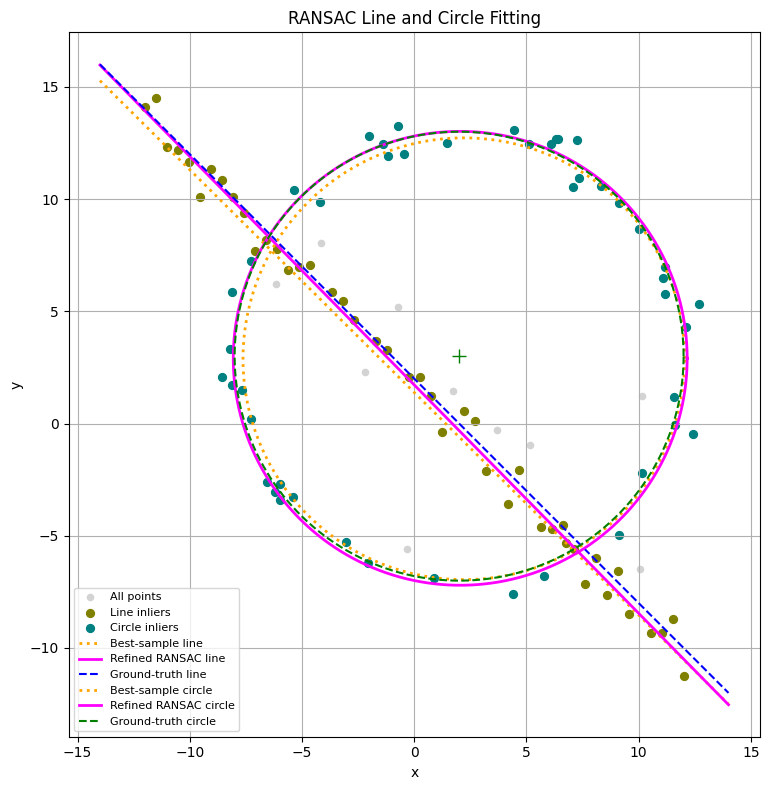

Best-sample line (a, b, d): [0.70429027 0.70991211 0.98338319]
Refined line (a, b, d): [-0.71326598 -0.70089346 -1.20609037]
Best-sample circle (cx, cy, r): [2.21174269 2.88488349 9.83977978]
Refined circle (cx, cy, r): [ 2.04861766  2.90507341 10.11035916]


,Model,Slope,Intercept,Center x,Center y,Radius,Inliers
0,Ground-truth line,-1.000,2.000,NaN,NaN,NaN,50
1,Refined line,-1.018,1.721,NaN,NaN,NaN,44
2,Ground-truth circle,NaN,NaN,2.000,3.000,10.00,50
3,Refined circle,NaN,NaN,2.049,2.905,10.11,46



Fitting-order comparison:


,Order,Line inliers,Circle inliers,Line slope,Line intercept,Circle cx,Circle cy,Circle radius
0,Line then circle,44,46,-1.018,1.721,2.049,2.905,10.11
1,Circle then line,38,52,-1.029,1.834,2.057,2.908,10.10



All Question 2 outputs saved in q2_outputs.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
# EN3160 Assignment 2 - Question 2
# RANSAC Line and Circle Fitting
# Includes iterative line refinement, circle refinement,
# fitting-order comparison, and report-ready outputs.

import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import os
import zipfile

from scipy.optimize import least_squares
from google.colab import files

np.random.seed(42)

OUTPUT_DIR = "q2_outputs"
os.makedirs(OUTPUT_DIR, exist_ok=True)

# ============================================================
# 1. GENERATE DATA USING THE LECTURER'S PROCEDURE
# ============================================================

N = 100
half_n = N // 2

# Circle points
cx_true, cy_true, r_true = 2.0, 3.0, 10.0

s_circle = r_true / 16
theta = np.random.uniform(0, 2*np.pi, half_n)
noise = s_circle * np.random.randn(half_n)

circle_points = np.column_stack((
    cx_true + (r_true + noise) * np.cos(theta),
    cy_true + (r_true + noise) * np.sin(theta)
))

# Line points: y = mx + b
m_true, b_true = -1.0, 2.0

s_line = 1.0
x_line = np.linspace(-12, 12, half_n)
y_line = m_true*x_line + b_true + s_line*np.random.randn(half_n)

line_points = np.column_stack((x_line, y_line))

# Combined noisy dataset
points = np.vstack((circle_points, line_points))


# ============================================================
# 2. LINE ESTIMATION AND PERPENDICULAR ERROR
# Model: ax + by = d, with a^2 + b^2 = 1
# ============================================================

def estimate_line(p1, p2):
    direction = p2 - p1

    if np.linalg.norm(direction) < 1e-10:
        return None

    # Unit normal perpendicular to the direction vector
    a = -direction[1]
    b = direction[0]
    norm = np.hypot(a, b)

    a /= norm
    b /= norm

    d = a*p1[0] + b*p1[1]

    return np.array([a, b, d])


def line_errors(pts, model):
    a, b, d = model

    # Because the normal is normalized, this is perpendicular distance.
    return np.abs(a*pts[:, 0] + b*pts[:, 1] - d)


def ransac_line(pts, threshold=1.0, iterations=3000):
    best_model = None
    best_inliers = None
    best_error = np.inf

    for _ in range(iterations):
        idx = np.random.choice(len(pts), 2, replace=False)

        model = estimate_line(pts[idx[0]], pts[idx[1]])

        if model is None:
            continue

        errors = line_errors(pts, model)
        inliers = errors < threshold
        count = inliers.sum()

        # Prefer the largest consensus; break ties by lower error.
        error_sum = errors[inliers].sum()

        if (
            best_inliers is None
            or count > best_inliers.sum()
            or (
                count == best_inliers.sum()
                and error_sum < best_error
            )
        ):
            best_model = model.copy()
            best_inliers = inliers.copy()
            best_error = error_sum

    return best_model, best_inliers


def refine_line_tls(pts):
    """Total least squares line fitting."""
    centroid = pts.mean(axis=0)
    centered = pts - centroid

    _, _, Vt = np.linalg.svd(centered, full_matrices=False)

    # Eigenvector/direction of minimum variation is the normal.
    normal = Vt[-1]
    normal /= np.linalg.norm(normal)

    a, b = normal
    d = a*centroid[0] + b*centroid[1]

    return np.array([a, b, d])


def refine_line_consensus(pts, initial_inliers, threshold=1.0,
                          max_iterations=20):
    """
    Iteratively refine the line using TLS and update its consensus.
    Returns the refined model and the final inlier mask.
    """
    inliers = initial_inliers.copy()

    for _ in range(max_iterations):
        if inliers.sum() < 2:
            break

        model = refine_line_tls(pts[inliers])
        new_inliers = line_errors(pts, model) < threshold

        if new_inliers.sum() < 2:
            break

        if np.array_equal(new_inliers, inliers):
            inliers = new_inliers
            break

        inliers = new_inliers

    model = refine_line_tls(pts[inliers])
    return model, inliers


def line_mb(model):
    """Convert ax + by = d to y = mx + b, when possible."""
    a, b, d = model

    if abs(b) < 1e-8:
        return np.nan, np.nan

    return -a/b, d/b


# ============================================================
# 3. CIRCLE ESTIMATION AND RADIAL ERROR
# ============================================================

def estimate_circle(p1, p2, p3):
    matrix = 2*np.array([
        [p2[0]-p1[0], p2[1]-p1[1]],
        [p3[0]-p1[0], p3[1]-p1[1]]
    ])

    rhs = np.array([
        p2@p2 - p1@p1,
        p3@p3 - p1@p1
    ])

    if abs(np.linalg.det(matrix)) < 1e-8:
        return None

    center = np.linalg.solve(matrix, rhs)
    radius = np.linalg.norm(center-p1)

    if not np.isfinite(radius) or radius <= 0:
        return None

    return np.array([center[0], center[1], radius])


def circle_errors(pts, model):
    cx, cy, radius = model

    distances = np.hypot(
        pts[:, 0]-cx,
        pts[:, 1]-cy
    )

    return np.abs(distances-radius)


def ransac_circle(pts, threshold=1.0, iterations=4000):
    best_model = None
    best_inliers = None
    best_error = np.inf

    for _ in range(iterations):
        idx = np.random.choice(len(pts), 3, replace=False)

        model = estimate_circle(
            pts[idx[0]],
            pts[idx[1]],
            pts[idx[2]]
        )

        if model is None:
            continue

        errors = circle_errors(pts, model)
        inliers = errors < threshold
        count = inliers.sum()
        error_sum = errors[inliers].sum()

        if (
            best_inliers is None
            or count > best_inliers.sum()
            or (
                count == best_inliers.sum()
                and error_sum < best_error
            )
        ):
            best_model = model.copy()
            best_inliers = inliers.copy()
            best_error = error_sum

    return best_model, best_inliers


def refine_circle(pts):
    """Minimize squared radial errors."""
    x, y = pts[:, 0], pts[:, 1]

    # Algebraic initialization
    A = np.column_stack((2*x, 2*y, np.ones(len(pts))))
    rhs = x*x + y*y

    sol, *_ = np.linalg.lstsq(A, rhs, rcond=None)

    cx, cy = sol[0], sol[1]
    radius = np.sqrt(max(1e-12, sol[2] + cx**2 + cy**2))

    def residuals(params):
        cx, cy, radius = params
        return (
            np.hypot(pts[:, 0]-cx, pts[:, 1]-cy) - radius
        )

    result = least_squares(
        residuals,
        [cx, cy, radius],
        bounds=(
            [-np.inf, -np.inf, 1e-8],
            [np.inf, np.inf, np.inf]
        )
    )

    return result.x


def refine_circle_consensus(pts, initial_inliers, threshold=1.0,
                            max_iterations=20):
    """Refine circle and re-evaluate the radial-error consensus."""
    inliers = initial_inliers.copy()

    for _ in range(max_iterations):
        if inliers.sum() < 3:
            break

        model = refine_circle(pts[inliers])
        new_inliers = circle_errors(pts, model) < threshold

        if new_inliers.sum() < 3:
            break

        if np.array_equal(new_inliers, inliers):
            inliers = new_inliers
            break

        inliers = new_inliers

    model = refine_circle(pts[inliers])
    return model, inliers


# ============================================================
# 4. LINE FIRST, THEN CIRCLE
# ============================================================

LINE_THRESHOLD = 1.0
CIRCLE_THRESHOLD = 1.0

# RANSAC initial line
line_sample_model, line_sample_inliers = ransac_line(
    points,
    threshold=LINE_THRESHOLD
)

# Iterative line refinement
line_refined, line_inliers = refine_line_consensus(
    points,
    line_sample_inliers,
    threshold=LINE_THRESHOLD
)

# Remove the line consensus
remaining = points[~line_inliers]

# RANSAC circle on the remaining points
circle_sample_model, circle_sample_inliers = ransac_circle(
    remaining,
    threshold=CIRCLE_THRESHOLD
)

# Refine circle and update its consensus
circle_refined, circle_inliers = refine_circle_consensus(
    remaining,
    circle_sample_inliers,
    threshold=CIRCLE_THRESHOLD
)

circle_inlier_points = remaining[circle_inliers]


# ============================================================
# 5. CIRCLE FIRST, THEN LINE
# ============================================================

circle_first_sample, circle_first_mask = ransac_circle(
    points,
    threshold=CIRCLE_THRESHOLD
)

circle_first_refined, circle_first_inliers = refine_circle_consensus(
    points,
    circle_first_mask,
    threshold=CIRCLE_THRESHOLD
)

remaining_after_circle = points[~circle_first_inliers]

line_second_sample, line_second_mask = ransac_line(
    remaining_after_circle,
    threshold=LINE_THRESHOLD
)

line_second_refined, line_second_inliers = refine_line_consensus(
    remaining_after_circle,
    line_second_mask,
    threshold=LINE_THRESHOLD
)


# ============================================================
# 6. PLOT REQUIRED BY QUESTION 2(c)
# ============================================================

fig, ax = plt.subplots(figsize=(10, 8))

# All points
ax.scatter(
    points[:, 0], points[:, 1],
    s=20, color="lightgray", label="All points"
)

# Line inliers
ax.scatter(
    points[line_inliers, 0],
    points[line_inliers, 1],
    s=32, color="olive", label="Line inliers"
)

# Circle inliers
ax.scatter(
    circle_inlier_points[:, 0],
    circle_inlier_points[:, 1],
    s=32, color="teal", label="Circle inliers"
)

xx = np.linspace(-14, 14, 400)
t = np.linspace(0, 2*np.pi, 400)

# Best-sample line
a, b, d = line_sample_model

if abs(b) > 1e-8:
    ax.plot(
        xx, (d-a*xx)/b,
        color="orange", linestyle=":",
        linewidth=2, label="Best-sample line"
    )

# Refined line
a, b, d = line_refined

if abs(b) > 1e-8:
    ax.plot(
        xx, (d-a*xx)/b,
        color="magenta", linewidth=2,
        label="Refined RANSAC line"
    )

# Ground-truth line
ax.plot(
    xx, m_true*xx+b_true,
    color="blue", linestyle="--",
    linewidth=1.5, label="Ground-truth line"
)

# Best-sample circle
cx, cy, radius = circle_sample_model

ax.plot(
    cx+radius*np.cos(t),
    cy+radius*np.sin(t),
    color="orange", linestyle=":",
    linewidth=2, label="Best-sample circle"
)

# Refined circle
cx, cy, radius = circle_refined

ax.plot(
    cx+radius*np.cos(t),
    cy+radius*np.sin(t),
    color="magenta", linewidth=2,
    label="Refined RANSAC circle"
)

# Ground-truth circle
ax.plot(
    cx_true+r_true*np.cos(t),
    cy_true+r_true*np.sin(t),
    color="green", linestyle="--",
    linewidth=1.5, label="Ground-truth circle"
)

ax.plot(cx_true, cy_true, "g+", markersize=10)

ax.set_xlabel("x")
ax.set_ylabel("y")
ax.set_title("RANSAC Line and Circle Fitting")
ax.set_aspect("equal", adjustable="box")
ax.grid(True)
ax.legend(fontsize=8, loc="best")

plt.tight_layout()
plt.savefig(
    f"{OUTPUT_DIR}/01_complete_ransac_plot.png",
    dpi=300, bbox_inches="tight"
)
plt.show()


# ============================================================
# 7. PARAMETER COMPARISON
# ============================================================

m_est, b_est = line_mb(line_refined)

parameter_table = pd.DataFrame([
    {
        "Model": "Ground-truth line",
        "Slope": m_true,
        "Intercept": b_true,
        "Center x": np.nan,
        "Center y": np.nan,
        "Radius": np.nan,
        "Inliers": 50
    },
    {
        "Model": "Refined line",
        "Slope": m_est,
        "Intercept": b_est,
        "Center x": np.nan,
        "Center y": np.nan,
        "Radius": np.nan,
        "Inliers": int(line_inliers.sum())
    },
    {
        "Model": "Ground-truth circle",
        "Slope": np.nan,
        "Intercept": np.nan,
        "Center x": cx_true,
        "Center y": cy_true,
        "Radius": r_true,
        "Inliers": 50
    },
    {
        "Model": "Refined circle",
        "Slope": np.nan,
        "Intercept": np.nan,
        "Center x": circle_refined[0],
        "Center y": circle_refined[1],
        "Radius": circle_refined[2],
        "Inliers": int(circle_inliers.sum())
    }
])

print("Best-sample line (a, b, d):", line_sample_model)
print("Refined line (a, b, d):", line_refined)
print("Best-sample circle (cx, cy, r):", circle_sample_model)
print("Refined circle (cx, cy, r):", circle_refined)

display(parameter_table.round(3))

parameter_table.to_csv(
    f"{OUTPUT_DIR}/02_parameter_comparison.csv",
    index=False
)


# ============================================================
# 8. FITTING-ORDER COMPARISON FOR QUESTION 2(d)
# ============================================================

m_line2, b_line2 = line_mb(line_second_refined)

order_table = pd.DataFrame([
    {
        "Order": "Line then circle",
        "Line inliers": int(line_inliers.sum()),
        "Circle inliers": int(circle_inliers.sum()),
        "Line slope": m_est,
        "Line intercept": b_est,
        "Circle cx": circle_refined[0],
        "Circle cy": circle_refined[1],
        "Circle radius": circle_refined[2]
    },
    {
        "Order": "Circle then line",
        "Line inliers": int(line_second_inliers.sum()),
        "Circle inliers": int(circle_first_inliers.sum()),
        "Line slope": m_line2,
        "Line intercept": b_line2,
        "Circle cx": circle_first_refined[0],
        "Circle cy": circle_first_refined[1],
        "Circle radius": circle_first_refined[2]
    }
])

print("\nFitting-order comparison:")
display(order_table.round(3))

order_table.to_csv(
    f"{OUTPUT_DIR}/03_fitting_order_comparison.csv",
    index=False
)


# ============================================================
# 9. SAVE OUTPUTS
# ============================================================

with zipfile.ZipFile("q2_outputs.zip", "w") as zf:
    for filename in os.listdir(OUTPUT_DIR):
        zf.write(
            os.path.join(OUTPUT_DIR, filename),
            arcname=filename
        )

print("\nAll Question 2 outputs saved in q2_outputs.zip")
files.download("q2_outputs.zip")

Upload these four files:
  flag1.png       - Sri Lankan flag
  flag2.png       - Japanese flag
  building1.jpg   - First building
  building2.jpg   - Second building


Saving building1.jpg to building1.jpg
Saving building2.jpg to building2.jpg
Saving flag1.png to flag1.png
Saving flag2.png to flag2.png


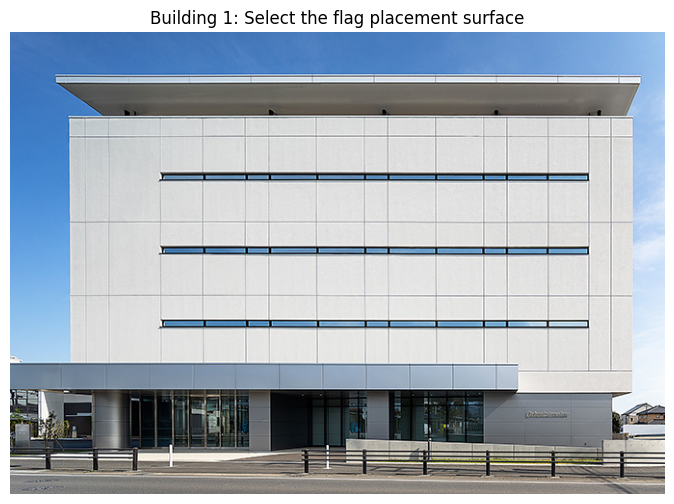

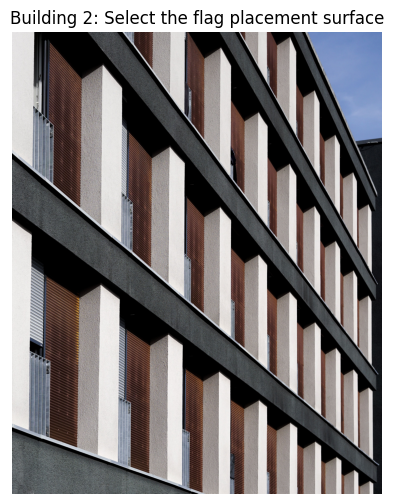


Building 1 - Sri Lankan Flag
Click the four corners in the specified order.
Each click will be marked on the image.


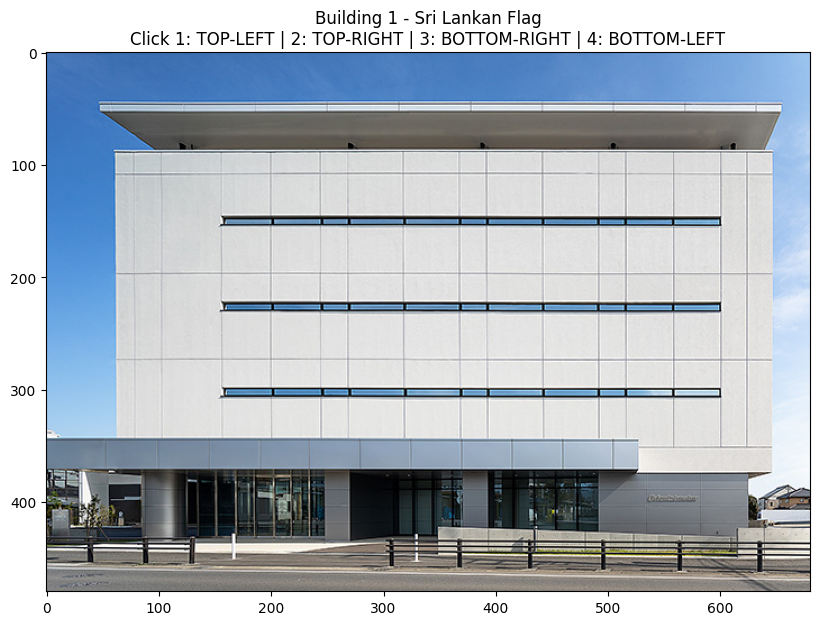

Waiting for corner 1/4...
Waiting for corner 1/4...
Waiting for corner 1/4...
Waiting for corner 1/4...
Waiting for corner 1/4...
Waiting for corner 1/4...
Waiting for corner 1/4...
Waiting for corner 1/4...
Waiting for corner 1/4...
Waiting for corner 1/4...
Waiting for corner 1/4...
Waiting for corner 1/4...
Waiting for corner 1/4...
Waiting for corner 1/4...
Waiting for corner 1/4...
Waiting for corner 1/4...
Waiting for corner 1/4...
Waiting for corner 1/4...
Waiting for corner 1/4...
Waiting for corner 1/4...
Waiting for corner 1/4...
Waiting for corner 1/4...
Waiting for corner 1/4...
Waiting for corner 1/4...
Waiting for corner 1/4...
Waiting for corner 1/4...
Waiting for corner 1/4...
Waiting for corner 1/4...
Waiting for corner 1/4...
Waiting for corner 1/4...
Waiting for corner 1/4...
Waiting for corner 1/4...
Waiting for corner 1/4...
Waiting for corner 1/4...
Waiting for corner 1/4...
Waiting for corner 1/4...
Waiting for corner 1/4...
Waiting for corner 1/4...
Waiting for 

KeyboardInterrupt: 

In [ ]:
# ============================================================
# EN3160 Assignment 2 - Question 3
# Homography and Perspective Warping of Flags onto Buildings
# ============================================================

import cv2
import numpy as np
import matplotlib.pyplot as plt
import os
import zipfile
from google.colab import files
from IPython.display import display, Image

# ------------------------------------------------------------
# 1. Upload the four images
# ------------------------------------------------------------

print("Upload these four files:")
print("  flag1.png       - Sri Lankan flag")
print("  flag2.png       - Japanese flag")
print("  building1.jpg   - First building")
print("  building2.jpg   - Second building")

uploaded = files.upload()

required_files = [
    "flag1.png",
    "flag2.png",
    "building1.jpg",
    "building2.jpg"
]

for filename in required_files:
    if filename not in uploaded:
        raise FileNotFoundError(
            f"Missing {filename}. Please upload all four required images."
        )

# Read images without discarding transparency
flag1 = cv2.imread("flag1.png", cv2.IMREAD_UNCHANGED)
flag2 = cv2.imread("flag2.png", cv2.IMREAD_UNCHANGED)
building1 = cv2.imread("building1.jpg", cv2.IMREAD_COLOR)
building2 = cv2.imread("building2.jpg", cv2.IMREAD_COLOR)

if any(img is None for img in [flag1, flag2, building1, building2]):
    raise ValueError("One or more images could not be loaded.")

# Convert building images from BGR to RGB for displaying
def show_image(title, image):
    if len(image.shape) == 3 and image.shape[2] == 4:
        image = cv2.cvtColor(image, cv2.COLOR_BGRA2RGBA)
    elif len(image.shape) == 3:
        image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

    plt.figure(figsize=(10, 6))
    plt.imshow(image)
    plt.title(title)
    plt.axis("off")
    plt.show()

show_image("Building 1: Select the flag placement surface", building1)
show_image("Building 2: Select the flag placement surface", building2)

# ------------------------------------------------------------
# 2. Interactive selection with visible click confirmation
# ------------------------------------------------------------

def select_corners(image, title):

    rgb = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

    fig, ax = plt.subplots(figsize=(12, 7))
    ax.imshow(rgb)
    ax.set_title(
        f"{title}\n"
        "Click 1: TOP-LEFT | 2: TOP-RIGHT | "
        "3: BOTTOM-RIGHT | 4: BOTTOM-LEFT"
    )
    ax.axis("on")

    corner_names = [
        "TOP-LEFT",
        "TOP-RIGHT",
        "BOTTOM-RIGHT",
        "BOTTOM-LEFT"
    ]

    points = []

    print(f"\n{title}")
    print("Click the four corners in the specified order.")
    print("Each click will be marked on the image.")

    # Keep the image open and register each click immediately
    def onclick(event):

        if event.inaxes != ax:
            return

        if len(points) >= 4:
            print("All four corners have already been selected.")
            return

        if event.xdata is None or event.ydata is None:
            return

        x, y = float(event.xdata), float(event.ydata)
        index = len(points)
        points.append([x, y])

        # Mark the selected corner
        ax.plot(x, y, "ro", markersize=9)
        ax.annotate(
            f"{index + 1}: {corner_names[index]}",
            (x, y),
            xytext=(8, 8),
            textcoords="offset points",
            color="yellow",
            fontsize=10,
            fontweight="bold",
            bbox=dict(facecolor="black", alpha=0.7)
        )

        # Update the title to confirm progress
        if len(points) < 4:
            ax.set_title(
                f"{title}\n"
                f"Detected {len(points)}/4 corners. "
                f"Next: {corner_names[len(points)]}"
            )
        else:
            ax.set_title(
                f"{title}\n"
                "All 4 corners selected! Close the figure to continue."
            )

        fig.canvas.draw_idle()

        print(
            f"Corner {index + 1}/4 detected: "
            f"{corner_names[index]} at (x={x:.1f}, y={y:.1f})"
        )

    connection_id = fig.canvas.mpl_connect(
        "button_press_event", onclick
    )

    plt.show()

    # Wait until four corners have been selected
    while len(points) < 4:
        print(f"Waiting for corner {len(points) + 1}/4...")
        plt.pause(0.5)

    fig.canvas.mpl_disconnect(connection_id)

    points = np.array(points, dtype=np.float32)

    print(f"\nSUCCESS: All 4 corners selected for {title}!")
    print("Coordinates (x, y):")
    print(points)

    return points


# Select corners for both buildings
dst1 = select_corners(
    building1,
    "Building 1 - Sri Lankan Flag"
)

dst2 = select_corners(
    building2,
    "Building 2 - Japanese Flag"
)

# ------------------------------------------------------------
# 3. Homography and flag warping
# ------------------------------------------------------------

def warp_flag_onto_building(flag, building, destination_points,
                            output_name):

    h_building, w_building = building.shape[:2]

    # Source corners of the complete flag image
    h_flag, w_flag = flag.shape[:2]

    source_points = np.array([
        [0, 0],
        [w_flag - 1, 0],
        [w_flag - 1, h_flag - 1],
        [0, h_flag - 1]
    ], dtype=np.float32)

    # Estimate the homography matrix
    H = cv2.getPerspectiveTransform(
        source_points,
        destination_points.astype(np.float32)
    )

    print(f"\nHomography matrix for {output_name}:")
    print(H)

    # Separate the flag's colour and transparency mask
    if len(flag.shape) == 3 and flag.shape[2] == 4:
        flag_bgr = flag[:, :, :3]
        source_mask = flag[:, :, 3]
    elif len(flag.shape) == 3 and flag.shape[2] == 3:
        flag_bgr = flag
        source_mask = np.full(
            (h_flag, w_flag), 255, dtype=np.uint8
        )
    else:
        raise ValueError("Flag must be a colour image.")

    # Warp the flag and its mask into the building image
    warped_flag = cv2.warpPerspective(
        flag_bgr, H, (w_building, h_building)
    )

    warped_mask = cv2.warpPerspective(
        source_mask, H, (w_building, h_building)
    )

    # Smooth the mask edges slightly to reduce harsh boundaries
    warped_mask = cv2.GaussianBlur(warped_mask, (3, 3), 0)

    # Blend flag with the building only where the flag is present
    alpha = (warped_mask.astype(np.float32) / 255.0) * 0.85
    alpha = alpha[:, :, np.newaxis]

    result = (
        building.astype(np.float32) * (1 - alpha)
        + warped_flag.astype(np.float32) * alpha
    )

    result = np.clip(result, 0, 255).astype(np.uint8)

    # Save results
    cv2.imwrite(output_name, result)
    cv2.imwrite(
        output_name.replace(".jpg", "_warped_flag.png"),
        warped_flag
    )
    cv2.imwrite(
        output_name.replace(".jpg", "_mask.png"),
        warped_mask
    )

    # Display original and final result
    fig, axes = plt.subplots(1, 2, figsize=(16, 7))

    axes[0].imshow(cv2.cvtColor(building, cv2.COLOR_BGR2RGB))
    axes[0].set_title("Original Building")
    axes[0].axis("off")

    axes[1].imshow(cv2.cvtColor(result, cv2.COLOR_BGR2RGB))
    axes[1].set_title("Flag Warped onto Building")
    axes[1].axis("off")

    plt.tight_layout()
    plt.show()

    return result, H

# ------------------------------------------------------------
# 4. Apply homography to both image pairs
# ------------------------------------------------------------

result1, H1 = warp_flag_onto_building(
    flag1,
    building1,
    dst1,
    "building1_result.jpg"
)

result2, H2 = warp_flag_onto_building(
    flag2,
    building2,
    dst2,
    "building2_result.jpg"
)

# ------------------------------------------------------------
# 5. Save a comparison figure
# ------------------------------------------------------------

fig, axes = plt.subplots(2, 2, figsize=(14, 12))

axes[0, 0].imshow(cv2.cvtColor(building1, cv2.COLOR_BGR2RGB))
axes[0, 0].set_title("Original Building 1")
axes[0, 0].axis("off")

axes[0, 1].imshow(cv2.cvtColor(result1, cv2.COLOR_BGR2RGB))
axes[0, 1].set_title("Sri Lankan Flag - Warped Result")
axes[0, 1].axis("off")

axes[1, 0].imshow(cv2.cvtColor(building2, cv2.COLOR_BGR2RGB))
axes[1, 0].set_title("Original Building 2")
axes[1, 0].axis("off")

axes[1, 1].imshow(cv2.cvtColor(result2, cv2.COLOR_BGR2RGB))
axes[1, 1].set_title("Japanese Flag - Warped Result")
axes[1, 1].axis("off")

plt.tight_layout()
plt.savefig("Q3_comparison.png", dpi=200, bbox_inches="tight")
plt.show()

# Save homography matrices
np.savetxt("homography_building1.txt", H1, fmt="%.8f")
np.savetxt("homography_building2.txt", H2, fmt="%.8f")

# ------------------------------------------------------------
# 6. Package all outputs into a ZIP file
# ------------------------------------------------------------

output_files = [
    "building1_result.jpg",
    "building1_result_warped_flag.png",
    "building1_result_mask.png",
    "building2_result.jpg",
    "building2_result_warped_flag.png",
    "building2_result_mask.png",
    "Q3_comparison.png",
    "homography_building1.txt",
    "homography_building2.txt"
]

with zipfile.ZipFile("Q3_results.zip", "w") as zipf:
    for filename in output_files:
        if os.path.exists(filename):
            zipf.write(filename)

print("\nQuestion 3 completed!")
print("Results saved in Q3_results.zip")

files.download("Q3_results.zip")